### **Student Information**
Name (optional): 劉俊吾

Student ID (optional): 115062506

GitHub ID: 76562622

Github Username : liu-chun-wu

Kaggle name: Chun Wu Liu

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a backup ZIP on the corresponding NTU COOL assignment. The ZIP should contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

**Summary.** The final model averages the class probabilities of 11 fine-tuned transformer runs (five fold models each, 55 models in total) and predicts the most probable emotion. Its 5-fold cross-validated (CV) macro F1 is **0.624 ± 0.026**, against **0.515** for the TF-IDF + linear SVM baseline. On Kaggle it scored **0.6127** on the public leaderboard (submission 58234174). Every number below is printed by the code cell named in brackets, for example *(3.6)*.

### 1.1 Preprocessing Steps

**Loading** *(1.0)*. `final_posts.json` (text), `data_identification.csv` (train/test split) and `emotion.csv` (labels) are joined on `post_id`: 3,360 labelled training posts and 1,440 test posts. The same cell finds the data on Kaggle (`/kaggle/input/...`) and locally, so the notebook runs unchanged in both places.

**Validation before modelling** *(1.1)*. Each check led to a decision:

| Finding | Decision |
| --- | --- |
| The classes are imbalanced: joy 26.0%, anger 20.1%, sadness 18.7%, disgust 13.5%, surprise 13.1%, fear 8.6%. The metric is macro F1 (checked with a constant all-`joy` probe submission, which scored 0.0686), so fear counts as much as joy. | Balanced class weights for the SVM; per-class F1 reported for every model. |
| Posts are short: median 13 words, mean 16.5, longest 508. | A 128-token limit for transformers (see below). |
| 50 texts occur twice (100 posts); 16 of them carry two different labels, 7 of those anger vs disgust. | Kept as they are. They show label noise, and they reappear in the error analysis (1.3). |
| 59 test posts have exactly the same text as a training post. | Tested an exact-match override in 3.7; rejected (see 1.3). |
| 236 posts contain the anonymised placeholder `[NAME]`; none contain a URL. | `[NAME]` gets its own token (below). |

![Training posts per emotion](./pics/hw_class_distribution.png)

**Cleaning for TF-IDF** *(1.2)*. Lowercase; remove URLs (a safeguard, none occur); replace `[NAME]` with the single token `nameplaceholder` so it is not counted as the ordinary word "name"; collapse whitespace. Stop words are kept and no stemming is applied, because short emotional posts depend on words such as "not" and "no" (in the baseline SVM, "not" is the fifth-strongest of 37,102 word features for anger).

**Input for transformers** *(2.2)*. The transformers receive the raw text. Their tokenizers handle case and punctuation themselves, and capitals carry intensity ("I am shocked I tell you! SHOCKED!"). With the `roberta-base` tokenizer the median post is 19 tokens and the 95th percentile 45, so truncating at 128 tokens shortens only 27 of the 3,360 training posts (0.8%).

### 1.2 Feature Engineering Steps

**(a) TF-IDF features for the baseline** *(2.1)*. Two TF-IDF vectorizers are joined side by side:

- word unigrams and bigrams: 37,102 features;
- character n-grams of length 2–5 within word boundaries (`char_wb`): 55,593 features. They match spelling variants, elongations ("sooo"), hashtags and word fragments that whole-word features miss.

Both use sublinear term frequency ($1 + \log tf$), so a word repeated in one post does not dominate it. The effect of each step was measured with the same 5-fold CV during development:

| Features (LinearSVC) | CV macro F1 |
| --- | --- |
| word unigrams | 0.463 |
| + word bigrams | 0.466 |
| + character n-grams 2–5 | 0.496 |
| + balanced class weights | 0.500 |
| + sublinear tf, all n-grams kept (`min_df=1`), `[NAME]` token: final baseline *(3.2)* | **0.515** |

**(b) Learned features: pre-trained transformers** *(2.2, 3.4)*. A transformer splits a post into subword tokens (for example `SHOCKED` → `SH`, `OCK`, `ED`) and computes a contextual vector for every token. The classification head reads the vector of the first token (`<s>`, the `[CLS]` position) and maps it to six scores. Fine-tuning adjusts all layers, so the features are learned from the labels instead of designed by hand. Unlike TF-IDF, these features use word order and context, so "not happy" and "happy" get different representations.

Two kinds of pre-trained models were used:

- general English: `roberta-base`, `roberta-large`, `microsoft/deberta-v3-base`, `microsoft/deberta-v3-large`;
- tweet-domain models pre-trained by masked-language modelling on tweets: `cardiffnlp/twitter-roberta-base`, `cardiffnlp/twitter-roberta-base-2022-154m`, `cardiffnlp/twitter-roberta-large-2022-154m`.

Checkpoints already fine-tuned on emotion datasets were excluded on purpose: they may have been trained on the same public tweets as this test set, which would leak test labels into the model.

The learned features outperform the TF-IDF features clearly: every single transformer run scores 0.548–0.616 against 0.515 (figure in 1.3).

### 1.3 Explanation of Your Model

**Validation** *(3.1)*. All models use the same 5-fold stratified split of the training set (`random_state=42`). A model is scored by its macro F1 on each held-out fold; the report gives the mean ± standard deviation over the five folds. The public leaderboard is only a further test set seen through five submissions a day, so it was never used to choose models.

**Baseline** *(3.2, 3.3)*. TF-IDF features (1.2a) with a linear SVM (`LinearSVC`, `C=0.3` chosen by CV from 0.3 / 0.5 / 1.0, balanced class weights): CV 0.5153 ± 0.0139; public leaderboard 0.5159.

**Fine-tuning recipe** *(3.4)*. For each fold, a fresh copy of the pre-trained model gets a new six-way classification head and is trained on the other four folds:

- cross-entropy loss, AdamW (weight decay 0.01), batch size 16, maximum length 128 tokens;
- learning rate warmed up linearly over the first 10% of steps, then decayed linearly to 0;
- gradient clipping at 1.0; mixed precision (fp16) on a Kaggle T4 GPU.

After every epoch the model predicts its held-out fold (out-of-fold, OOF, probabilities) and the test posts. One epoch count is then chosen for **all** folds (the one with the best mean fold F1); picking the best epoch separately in each fold would overstate the CV score. Each run's test probabilities are the mean of its five fold models.

**The 11 runs** *(3.5)*. Large models need a smaller learning rate: at 1.5e-5 and above, `roberta-large` and `deberta-v3-large` collapsed on some folds during development (fold F1 0.069 and 0.186). A fixed rule therefore drops any run with a fold below 0.3; no run in the final set needed it.

| Run | Learning rate | Epochs (chosen) | CV macro F1 | GPU minutes |
| --- | --- | --- | --- | --- |
| roberta-large, seed 21 | 1e-5 | 4 | 0.6160 ± 0.0147 | 30 |
| roberta-large, seed 7 | 1e-5 | 6 | 0.6096 ± 0.0231 | 30 |
| roberta-large, seed 42 | 1e-5 | 4 | 0.6071 ± 0.0251 | 20 |
| twitter-roberta-base, seed 7 | 2e-5 | 2 | 0.6022 ± 0.0239 | 7 |
| twitter-roberta-base, seed 42 | 2e-5 | 2 | 0.6009 ± 0.0203 | 9 |
| roberta-base, seed 42 | 2e-5 | 3 | 0.5983 ± 0.0208 | 9 |
| roberta-base, seed 7 | 2e-5 | 3 | 0.5973 ± 0.0177 | 7 |
| twitter-roberta-base-2022-154m | 2e-5 | 3 | 0.5969 ± 0.0145 | 7 |
| deberta-v3-base | 3e-5 | 5 | 0.5948 ± 0.0214 | 17 |
| twitter-roberta-large-2022-154m | 1e-5 | 6 | 0.5944 ± 0.0302 | 30 |
| deberta-v3-large | 1e-5 | 5 | 0.5480 ± 0.0613 | 37 |

**Final model: plain average** *(3.6)*. The predicted emotion is the argmax of the mean probability over the 11 runs. A plain average has nothing to tune, so its CV score needs no correction for selection, and runs with different backbones and seeds make partly different mistakes. CV macro F1 **0.6242 ± 0.0259** (folds 0.608, 0.595, 0.654, 0.656, 0.607), micro F1 0.647: +0.008 over the best single run and +0.109 over the baseline.

![Cross-validated macro F1 by model](./pics/hw_cv_comparison.png)

Per-class F1, baseline → final ensemble: anger 0.510 → 0.614, disgust 0.371 → 0.444, fear 0.529 → 0.659, joy 0.638 → 0.770, sadness 0.560 → 0.660, surprise 0.490 → 0.598. Every class improves; disgust remains the weakest.

**Alternatives tested and rejected** *(3.7)*. Each tunable choice was made on four folds and scored on the fifth ("nested"), so it competes fairly with the plain average:

| Variant | CV macro F1 | Why rejected |
| --- | --- | --- |
| plain average (final) | **0.6242** | |
| + TF-IDF logistic-regression probabilities, nested weight | 0.6199 | The transformers already capture what TF-IDF adds. |
| + per-class offsets on the log-probabilities, nested | 0.6131 | The offsets chosen on different folds disagree, so they fit noise. |
| + exact-match override (copy the training label of an identical text) | 0.6223 | Most identical texts were already predicted correctly, and duplicate labels conflict. |

**Error analysis** *(3.8, 3.9)*. Adding both directions of every pair, anger ↔ disgust is the most-confused pair (186 posts), well ahead of anger ↔ sadness (133). The confusion is one-sided: 132 of the 454 disgust posts are predicted as anger, while only 54 of the 674 anger posts go the other way.

![Ensemble confusion matrix](./pics/hw_confusion_matrix.png)

- The errors are near misses: in 83% of them disgust is the second choice.
- The model has learned explicit disgust vocabulary. 17.5% of correctly classified disgust posts contain "disgusting", and none of the misclassified ones do. The misclassified posts instead contain hostile words that mark anger elsewhere in the data ("fucking" 5.3% vs 0%, "hate" 6.1% vs 0.6%, "stupid" 3.0% vs 0%).
- The labels themselves are ambiguous at this boundary: 7 of the 16 duplicated texts with conflicting labels are anger vs disgust. Profane complaints such as "Fucking refs suck my balls." are labelled disgust, and the model predicts anger with probability 0.91.

Part of the remaining error is therefore label ambiguity that no model can resolve from the text alone. The per-class offsets above tried to shift predictions towards disgust and lowered the CV score.

**Leaderboard.**

| Submission | CV macro F1 | Public leaderboard |
| --- | --- | --- |
| TF-IDF + LinearSVC (58196379) | 0.5153 | 0.5159 |
| average of 8 transformer runs (58233138) | 0.6218 | 0.6042 |
| **average of 11 transformer runs, final (58234174)** | **0.6242** | **0.6127** |

The public score of the final model lies within one fold standard deviation of its CV score. Private leaderboard score and rank: added after the competition closes on 2026-11-22.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

**Tool and way of working.** I used Claude Code, an AI coding agent (Anthropic's Claude Opus model) running in my repository, with access to the Kaggle command-line tool and Kaggle's MCP server. I set the goal, the constraints and the approvals. The agent proposed techniques, wrote and ran the code (locally and in private Kaggle GPU notebooks on my account), and reported the cross-validated result of each idea. It kept a running log of every suggestion, my decision and the measured effect; this section is written from that log. The rules I gave it:

- edit only this Homework notebook (I completed the Master and AgentPipeline notebooks myself);
- never submit to Kaggle without my explicit confirmation (I approved each of the submissions listed in 1.3);
- stop at the end of each planned phase and continue only after my approval;
- goal: public macro F1 ≥ 0.63; stop adding models once an addition improves CV by less than 0.005.

**My prompts** (quoted verbatim, in order; short replies such as "ok continue" after each phase are grouped):

| Date | Prompt | What followed |
| --- | --- | --- |
| 11-10 | "i approve the plan, execute" (my plan for setting up the whole lab) | Among the setup tasks, the agent built a first TF-IDF baseline and measured it with 5-fold CV (0.463 → 0.500, table below). |
| 11-10 | "check kaggle mcp functions / can you access competition submissions" | It confirmed that Kaggle's MCP server can read the competition and my submissions. |
| 11-10 | "Read reference/next-session.md and .claude/CLAUDE.md, then do Task 1 and Task 2. Stop before any Kaggle submission and ask me first." | Task 1: it read the rules, data and evaluation pages and the public leaderboard (6 emotions, 3,360 / 1,440 posts, "F1 Score", 5 submissions a day). Task 2: it settled two open questions with probe submissions. The first probe used `sampleSubmission.csv`'s header `post_id,label` and was rejected, which showed that the Evaluation page's `id,label` is correct. |
| 11-10 | "upload both" | The baseline (public 0.5159) and a constant all-`joy` probe (0.0686), which identifies **macro** F1. |
| 11-11 | "1. You will finsh homework part first then we will generate reasonable prompt for section 1.4 2. confirm with me before any submission to kaggle … Plan for homework part, plan only" | A written plan with phases, done-criteria and the submission protocol. |
| 11-11 | "1. yes, for the Homework notebook only. The Master and AgentPipeline stay hands-off. 2. OK to create a private notebook there and use your GPU quota for training 3. your current goal is fine" | Plan updated: transformer training on Kaggle GPUs, goal 0.63, stopping rule. |
| 11-11 | "start executing the plan, stop when each phase is finished, proceed when i approved", then "ok continue" after each phase | Phases 1–3: baseline in the notebook, transformers, ensemble. |
| 11-11 | "submit now, then try some more for 0.63 threshold" | 8-run ensemble submitted (public 0.6042); a third round added large and tweet-domain models. |
| 11-11 | "ok submit" | 11-run ensemble submitted (public 0.6127, the final submission). |
| 11-11 | "yes go with option A" | Option A: move all training and ensembling into this notebook and run it end to end on a Kaggle GPU, so every number in the report is printed by the code above. |
| 11-12 | "continue phase 6", "continue phase 7" | Error analysis (cell 3.9) and this report. |

**Techniques the AI suggested and what I decided.** I accepted a suggestion only when it improved the 5-fold CV macro F1; ideas that lowered it were dropped even when they sounded reasonable.

| AI suggestion | Decision | Reason and measured effect |
| --- | --- | --- |
| Judge every model by 5-fold stratified CV macro F1, never by the public leaderboard | Adopted | The public leaderboard is part of the test set seen through 5 submissions a day; choosing by it would fit noise. All model choices in 1.3 use CV. |
| Probe the metric with a constant all-`joy` submission | Adopted | Macro, weighted and micro F1 predict 0.069, 0.108 and 0.260; Kaggle returned 0.0686, so the metric is macro F1. |
| Add character n-grams and balanced class weights to word TF-IDF | Adopted | CV 0.466 → 0.496 → 0.500. |
| Sublinear tf, keep rare n-grams (`min_df=1`), map `[NAME]` to one token | Adopted | CV 0.500 → 0.515 (final baseline). |
| Fine-tune pre-trained transformers on a Kaggle GPU with the same folds | Adopted | First run (`deberta-v3-base`, 4 epochs) CV 0.567 and still rising, so it was undertrained; with lr 3e-5 and more epochs 0.595. The first attempt crashed because the library loaded the model in half precision; loading full-precision weights fixed it. |
| Exclude checkpoints already fine-tuned on emotion datasets | Adopted | They may have been trained on the same public tweets as the test set, which would leak test labels. |
| Choose one epoch count for all folds | Adopted | Picking the best epoch per fold would overstate the CV score. |
| Try a tweet-domain backbone (`cardiffnlp/twitter-roberta-base`) | Adopted | CV 0.601, the best base-size model. |
| Average the probabilities of several runs (plain average) | Adopted | 3 runs 0.617 → 8 runs 0.622 → 11 runs 0.624, against 0.616 for the best single run. |
| Large models (`roberta-large`, `deberta-v3-large`) at learning rate 1e-5, and drop any run with a fold below 0.3 | Adopted | `roberta-large` became the best single model (0.616). Two runs at 1.5e-5 and 2e-5 collapsed on one fold (0.069, 0.186) and were dropped by the rule. |
| Blend TF-IDF logistic-regression probabilities into the ensemble | Rejected | Nested CV 0.620 vs 0.624 for the plain average. |
| Per-class offsets to favour weak classes such as disgust | Rejected | Nested CV 0.613; the offsets chosen on different folds disagreed. |
| Copy the training label for test texts that also appear in train | Rejected | CV 0.622; most of those posts were already predicted correctly, and duplicate labels conflict. |
| Greedy forward selection of ensemble members | Rejected | 0.620 ± 0.019 vs 0.618 for the plain average of the same pool: within noise, and it adds selection bias. |
| Stop when an addition improves CV by less than 0.005 | Adopted | Going from 8 to 11 runs added only +0.0024, so experimenting stopped. The 0.63 public goal was not reached (0.6127). |
| Run the whole notebook end to end on Kaggle (Option A) | Adopted | All 11 runs reproduced their earlier CV scores exactly (205 GPU minutes), and the notebook's submission file is identical to the submitted one. |
| Analyse the most-confused pair (the Lab Exercise 8 method) | Adopted | Showed that anger ↔ disgust errors come largely from ambiguous labels (1.3). |

**What I take from it.** The AI was most useful for running many careful experiments quickly and for keeping the evaluation honest (fixed folds, nested choices, a stopping rule). Four of its ensemble ideas did not survive measurement, which is why each suggestion was tested before it was used.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
# 1.0 Locate and load the competition data.
# On Kaggle the files are mounted somewhere under /kaggle/input/ (the exact
# sub-folder depends on how the competition is attached), so search for them;
# locally they live in data/competition/, which is kept out of git.
import json
from pathlib import Path

import pandas as pd


def find_data_dir():
    """Return the folder that holds final_posts.json, on Kaggle or locally."""
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for path in kaggle_root.rglob("final_posts.json"):
            return path.parent
    local = Path("data/competition")
    if (local / "final_posts.json").exists():
        return local
    raise FileNotFoundError("final_posts.json not found under /kaggle/input/ or data/competition/")


DATA_DIR = find_data_dir()
print("Data folder:", DATA_DIR)

# Four files, all keyed by post_id: the texts, the train/test split, and the
# training labels (the test labels are hidden on Kaggle).
with open(DATA_DIR / "final_posts.json", encoding="utf-8") as f:
    posts = pd.DataFrame(json.load(f))                      # post_id, text
split = pd.read_csv(DATA_DIR / "data_identification.csv")   # post_id, set
labels = pd.read_csv(DATA_DIR / "emotion.csv")              # post_id, label

# Join on post_id; test posts get no label (how="left").
df = posts.merge(split, on="post_id").merge(labels, on="post_id", how="left")
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)
print(f"posts: {len(posts)}, train: {len(train_df)}, test: {len(test_df)}")

Data folder: /kaggle/input/competitions/2026-dm-lab-2-private-competition
posts: 4800, train: 3360, test: 1440


In [2]:
# 1.1 Validate the data before modelling (the same checks as Lab Exercise 1).
import re

import numpy as np

assert train_df["label"].notna().all() and test_df["label"].isna().all()
counts = train_df["label"].value_counts()
print("Label counts (train):")
print(pd.DataFrame({"posts": counts, "share": (counts / len(train_df)).round(3)}))

lengths = train_df["text"].str.split().str.len()
print(f"\nWords per post: median {lengths.median():.0f}, mean {lengths.mean():.1f}, max {lengths.max()}")

# Texts that occur more than once in train, and how many carry conflicting labels.
dup = train_df[train_df.duplicated("text", keep=False)]
n_conflict = int((dup.groupby("text")["label"].nunique() > 1).sum())
print(f"Duplicated training texts: {dup['text'].nunique()} distinct texts in {len(dup)} posts, "
      f"{n_conflict} with conflicting labels")

# Test posts whose exact text also appears in train.
in_train = test_df["text"].isin(set(train_df["text"]))
print(f"Test posts whose text also appears in train: {int(in_train.sum())}")

has_name = train_df["text"].str.contains(r"\[NAME\]")
has_url = train_df["text"].str.contains(r"https?://|www\.")
print(f"Training posts with the [NAME] placeholder: {int(has_name.sum())}; with a URL: {int(has_url.sum())}")

Label counts (train):
          posts  share
label                 
joy         875  0.260
anger       674  0.201
sadness     628  0.187
disgust     454  0.135
surprise    441  0.131
fear        288  0.086

Words per post: median 13, mean 16.5, max 508
Duplicated training texts: 50 distinct texts in 100 posts, 16 with conflicting labels
Test posts whose text also appears in train: 59
Training posts with the [NAME] placeholder: 236; with a URL: 0


In [3]:
# 1.2 Clean the text for the TF-IDF model.
# - Lowercase, so "Happy" and "happy" count as one word.
# - Remove URLs (none in this data; kept as a safeguard).
# - Replace the anonymised "[NAME]" with a single token, so it is not read as
#   the ordinary word "name".
# - Collapse repeated whitespace.
# A transformer model gets the raw text instead, because its tokenizer handles
# case and punctuation itself.
URL_RE = re.compile(r"https?://\S+|www\.\S+")


def clean_text(text):
    text = text.lower()
    text = URL_RE.sub(" ", text)
    text = text.replace("[name]", " nameplaceholder ")
    return re.sub(r"\s+", " ", text).strip()


train_df["text_clean"] = train_df["text"].map(clean_text)
test_df["text_clean"] = test_df["text"].map(clean_text)
print(train_df.loc[has_name, ["text", "text_clean"]].head(3).to_string(max_colwidth=70))

                                                                     text                                                             text_clean
11                        [NAME]? Rape? I am shocked I tell you! SHOCKED!              nameplaceholder ? rape? i am shocked i tell you! shocked!
21  Was against Cal but yeah [NAME] had a cannon of a leg but was very...  was against cal but yeah nameplaceholder had a cannon of a leg but...
25  Wow. [NAME] is a giant POS. He'll be really happy being single and...  wow. nameplaceholder is a giant pos. he'll be really happy being s...


## 2. Feature Engineering Steps

In [4]:
# 2.1 TF-IDF features: word and character n-grams side by side.
# - Word 1-2 grams capture short phrases such as "not happy".
# - Character 2-5 grams inside word boundaries (char_wb) catch misspellings,
#   elongations ("soooo") and word pieces, the same advantage FastText showed
#   over Word2Vec in the Master notebook.
# - sublinear_tf replaces a raw count tf with 1 + log(tf), so one word repeated
#   many times in a post does not dominate it.
# The vectorizers are fitted inside each CV fold in Section 3, never on the
# validation posts.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion


def build_tfidf():
    return FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
    ])


# Fitted once on all training posts here only to report the feature counts.
tfidf = build_tfidf().fit(train_df["text_clean"])
for name, vec in tfidf.transformer_list:
    print(f"{name} n-gram features: {len(vec.vocabulary_):,}")

word n-gram features: 37,102
char n-gram features: 55,593


In [5]:
# 2.2 Transformer inputs: subword tokens instead of hand-made features.
# A pre-trained transformer reads the raw text (case, punctuation and emojis
# kept), split into subword tokens from its own vocabulary, and learns its
# features during fine-tuning (Section 3). Posts are cut at MAX_LEN tokens;
# the check below shows how many posts that affects.
from transformers import AutoTokenizer

MAX_LEN = 128
tok_check = AutoTokenizer.from_pretrained("roberta-base")
n_tokens = train_df["text"].map(lambda t: len(tok_check(t)["input_ids"]))
print("Tokens per post (roberta-base tokenizer):",
      n_tokens.describe(percentiles=[0.5, 0.95, 0.99])[["50%", "95%", "99%", "max"]].to_dict())
print(f"Posts longer than {MAX_LEN} tokens (truncated): {int((n_tokens > MAX_LEN).sum())} of {len(n_tokens)}")
print("Example:", train_df.at[11, "text"])
print("Tokens: ", tok_check.tokenize(train_df.at[11, "text"]))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokens per post (roberta-base tokenizer): {'50%': 19.0, '95%': 45.0, '99%': 111.81999999999971, 'max': 511.0}
Posts longer than 128 tokens (truncated): 27 of 3360
Example: [NAME]? Rape? I am shocked I tell you! SHOCKED!
Tokens:  ['[', 'NAME', ']', '?', 'ĠRape', '?', 'ĠI', 'Ġam', 'Ġshocked', 'ĠI', 'Ġtell', 'Ġyou', '!', 'ĠSH', 'OCK', 'ED', '!']


## 3. Model Implementation Steps

In [6]:
# 3.1 Evaluation setup: 5-fold stratified cross-validation (CV).
# Every model in this notebook is scored on the same five folds, so their CV
# numbers are directly comparable. Macro F1 is the competition metric; the
# public leaderboard is only one more test set, so models are chosen by CV.
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

SEED = 42
N_FOLDS = 5
LABELS = sorted(train_df["label"].unique())

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df["fold"] = -1
for k, (_, val_idx) in enumerate(skf.split(train_df, train_df["label"])):
    train_df.loc[val_idx, "fold"] = k
print("Posts per fold and label:")
print(train_df.groupby("fold")["label"].value_counts().unstack())


def cv_report(name, oof_pred, verbose=True):
    """Score out-of-fold (OOF) predictions: macro F1 per fold, their mean and
    spread, pooled macro and micro F1, then (if verbose) the per-class report
    and the confusion matrix (rows = true label, columns = predicted)."""
    y = train_df["label"].values
    folds = train_df["fold"].values
    fold_f1 = [f1_score(y[folds == k], oof_pred[folds == k], average="macro") for k in range(N_FOLDS)]
    print(f"{name}: macro F1 per fold {np.round(fold_f1, 4)}")
    print(f"  mean {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f} | pooled OOF macro "
          f"{f1_score(y, oof_pred, average='macro'):.4f}, micro {f1_score(y, oof_pred, average='micro'):.4f}")
    if verbose:
        print(classification_report(y, oof_pred, labels=LABELS, digits=3))
        cm = pd.DataFrame(confusion_matrix(y, oof_pred, labels=LABELS), index=LABELS, columns=LABELS)
        print("Confusion matrix (rows = true, columns = predicted):")
        print(cm)
    return float(np.mean(fold_f1))

Posts per fold and label:
label  anger  disgust  fear  joy  sadness  surprise
fold                                               
0        135       91    57  175      126        88
1        135       91    57  175      126        88
2        135       91    58  175      125        88
3        135       91    58  175      125        88
4        134       90    58  175      126        89


In [7]:
# 3.2 Baseline model: a linear SVM on the TF-IDF features.
# class_weight="balanced" up-weights the rarer emotions (fear has 288 posts,
# joy 875), which helps macro F1. The regularisation strength C is compared on
# the CV folds; the vectorizers are refitted inside every fold, so the
# validation posts never shape the vocabulary.
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC


def build_svm(C):
    return make_pipeline(build_tfidf(), LinearSVC(C=C, class_weight="balanced", random_state=SEED))


def oof_predict(build_model):
    """Train on four folds, predict the fifth, for every fold."""
    oof = np.empty(len(train_df), dtype=object)
    for k in range(N_FOLDS):
        is_val = (train_df["fold"] == k).values
        model = build_model().fit(train_df.loc[~is_val, "text_clean"], train_df.loc[~is_val, "label"])
        oof[is_val] = model.predict(train_df.loc[is_val, "text_clean"])
    return oof


cv_by_C = {}
for C in [0.3, 0.5, 1.0]:
    cv_by_C[C] = cv_report(f"TF-IDF + LinearSVC, C={C}", oof_predict(lambda: build_svm(C)), verbose=False)
BEST_C = max(cv_by_C, key=cv_by_C.get)
print(f"\nChosen C = {BEST_C} (CV macro F1 {cv_by_C[BEST_C]:.4f}); full report:\n")
oof_svm = oof_predict(lambda: build_svm(BEST_C))
cv_svm = cv_report(f"TF-IDF + LinearSVC, C={BEST_C}", oof_svm)

TF-IDF + LinearSVC, C=0.3: macro F1 per fold [0.5312 0.4931 0.5234 0.5057 0.5233]
  mean 0.5153 ± 0.0139 | pooled OOF macro 0.5165, micro 0.5363


TF-IDF + LinearSVC, C=0.5: macro F1 per fold [0.5307 0.4957 0.5187 0.5015 0.5181]
  mean 0.5130 ± 0.0127 | pooled OOF macro 0.5141, micro 0.5333


TF-IDF + LinearSVC, C=1.0: macro F1 per fold [0.5375 0.4898 0.5206 0.5074 0.5087]
  mean 0.5128 ± 0.0158 | pooled OOF macro 0.5138, micro 0.5327

Chosen C = 0.3 (CV macro F1 0.5153); full report:



TF-IDF + LinearSVC, C=0.3: macro F1 per fold [0.5312 0.4931 0.5234 0.5057 0.5233]
  mean 0.5153 ± 0.0139 | pooled OOF macro 0.5165, micro 0.5363
              precision    recall  f1-score   support

       anger      0.483     0.542     0.510       674
     disgust      0.416     0.335     0.371       454
        fear      0.596     0.476     0.529       288
         joy      0.615     0.664     0.638       875
     sadness      0.554     0.567     0.560       628
    surprise      0.501     0.478     0.490       441

    accuracy                          0.536      3360
   macro avg      0.527     0.510     0.516      3360
weighted avg      0.534     0.536     0.533      3360

Confusion matrix (rows = true, columns = predicted):
          anger  disgust  fear  joy  sadness  surprise
anger       365       68    25   92       71        53
disgust     127      152    20   65       55        35
fear         39       21   137   41       33        17
joy          87       43    19  581    

In [8]:
# 3.3 Fit the baseline on all training posts and write its submission file.
# Kaggle expects the header id,label (sampleSubmission.csv's post_id header is
# rejected), one row per test post, and only the six emotion labels.
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def check_submission(sub):
    """Stop before a malformed file wastes one of the five daily submissions."""
    assert list(sub.columns) == ["id", "label"], "header must be id,label"
    assert len(sub) == len(test_df) and sub["id"].is_unique, "one row per test post"
    assert set(sub["id"]) == set(test_df["post_id"]), "ids must match the test posts"
    assert set(sub["label"]) <= set(LABELS), "unknown label"


svm_full = build_svm(BEST_C).fit(train_df["text_clean"], train_df["label"])
sub_svm = pd.DataFrame({"id": test_df["post_id"], "label": svm_full.predict(test_df["text_clean"])})
check_submission(sub_svm)
sub_svm.to_csv(OUT_DIR / "submission_tfidf_svm.csv", index=False)
print("Saved", OUT_DIR / "submission_tfidf_svm.csv")
print("Predicted label counts on the test posts:")
print(sub_svm["label"].value_counts())

Saved /kaggle/working/submission_tfidf_svm.csv
Predicted label counts on the test posts:
label
joy         414
anger       321
sadness     267
surprise    178
disgust     148
fear        112
Name: count, dtype: int64


In [9]:
# 3.4 Fine-tune a pre-trained transformer with the same 5-fold CV.
# For each fold, a fresh copy of the pre-trained model gets a new
# classification head and is trained on the other four folds. After every
# epoch it predicts its validation fold (out-of-fold, OOF, probabilities) and
# the test posts. One epoch count is then chosen for ALL folds (the best mean
# fold macro F1), so the CV score is not inflated by picking the best epoch
# separately in each fold.
# Settings: max length 128 tokens, batch 16, AdamW with weight decay 0.01,
# linear warm-up over 10% of the steps then linear decay, gradient clipping at
# 1.0, and mixed precision (fp16) on the GPU.
import math
import random
import time

import torch
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()      # hide the per-load weight report (the new head is expected to be untrained)
hf_logging.disable_progress_bar()

BATCH = 16
WEIGHT_DECAY = 0.01
WARMUP = 0.1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
RUN_DIR = OUT_DIR / "runs"
y_idx = train_df["label"].map({lab: i for i, lab in enumerate(LABELS)}).values
print("Device:", torch.cuda.get_device_name(0) if USE_AMP else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def batches(enc, idx, size):
    """Yield (row indices, token features) for consecutive slices of idx."""
    keys = list(enc.keys())
    for start in range(0, len(idx), size):
        chunk = idx[start:start + size]
        yield chunk, [{k: enc[k][i] for k in keys} for i in chunk]


@torch.no_grad()
def predict_proba(model, tok, enc, idx):
    model.eval()
    out = []
    for _, feats in batches(enc, idx, 64):
        inputs = tok.pad(feats, return_tensors="pt").to(DEVICE)   # pad to the longest post in the batch
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(**inputs).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


def fine_tune_cv(name, lr, epochs, seed=SEED):
    """Fine-tune `name` on every fold. Returns OOF probabilities, test
    probabilities averaged over the five fold models, and the CV scores."""
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(name)
    enc_train = tok(list(train_df["text"]), truncation=True, max_length=MAX_LEN)
    enc_test = tok(list(test_df["text"]), truncation=True, max_length=MAX_LEN)
    folds = train_df["fold"].values
    n_cls = len(LABELS)
    oof_by_epoch = np.zeros((epochs, len(train_df), n_cls), dtype=np.float32)
    test_by_epoch = np.zeros((epochs, N_FOLDS, len(test_df), n_cls), dtype=np.float32)
    fold_f1 = np.zeros((epochs, N_FOLDS))
    for k in range(N_FOLDS):
        set_seed(seed + k)
        tr_idx, va_idx = np.where(folds != k)[0], np.where(folds == k)[0]
        # fp32 master weights (some checkpoints are stored in fp16); the
        # forward pass still runs in fp16 through autocast.
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=n_cls, dtype=torch.float32).to(DEVICE)
        no_decay = ("bias", "LayerNorm.weight", "layernorm", "layer_norm")
        params = [
            {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
             "weight_decay": WEIGHT_DECAY},
            {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
             "weight_decay": 0.0},
        ]
        opt = torch.optim.AdamW(params, lr=lr)
        total_steps = math.ceil(len(tr_idx) / BATCH) * epochs
        sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total_steps), total_steps)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        rng = np.random.RandomState(seed + k)
        for ep in range(epochs):
            model.train()
            for chunk, feats in batches(enc_train, tr_idx[rng.permutation(len(tr_idx))], BATCH):
                inputs = tok.pad(feats, return_tensors="pt").to(DEVICE)
                target = torch.tensor(y_idx[chunk], device=DEVICE)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    loss = torch.nn.functional.cross_entropy(model(**inputs).logits.float(), target)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                opt.zero_grad(set_to_none=True)
            oof_by_epoch[ep, va_idx] = predict_proba(model, tok, enc_train, va_idx)
            test_by_epoch[ep, k] = predict_proba(model, tok, enc_test, np.arange(len(test_df)))
            fold_f1[ep, k] = f1_score(y_idx[va_idx], oof_by_epoch[ep, va_idx].argmax(1), average="macro")
        print(f"  fold {k}: val macro F1 by epoch {np.round(fold_f1[:, k], 4)}", flush=True)
        del model, opt
        if USE_AMP:
            torch.cuda.empty_cache()
    best = int(fold_f1.mean(axis=1).argmax())
    return {"oof": oof_by_epoch[best], "test": test_by_epoch[best].mean(axis=0), "fold_f1": fold_f1[best],
            "epochs": best + 1, "minutes": (time.time() - t0) / 60}

Device: Tesla T4


In [10]:
# 3.5 Train every model setting used in the final ensemble.
# Three families of general pre-trained encoders, none of them fine-tuned on
# emotion labels before: RoBERTa (base, large), Twitter-RoBERTa (pre-trained on
# tweets; base, large) and DeBERTa-v3 (base, large). Repeating a setting with
# another seed adds variety for the ensemble. The large models use a lower
# learning rate: at 1.5e-5 and above they diverged on some folds in earlier
# experiments. "epochs" is the maximum; the CV chooses the actual count.
RUNS = [
    {"name": "cardiffnlp/twitter-roberta-base", "lr": 2e-5, "epochs": 5},
    {"name": "cardiffnlp/twitter-roberta-base", "lr": 2e-5, "epochs": 4, "seed": 7},
    {"name": "cardiffnlp/twitter-roberta-base-2022-154m", "lr": 2e-5, "epochs": 4},
    {"name": "roberta-base", "lr": 2e-5, "epochs": 5},
    {"name": "roberta-base", "lr": 2e-5, "epochs": 4, "seed": 7},
    {"name": "microsoft/deberta-v3-base", "lr": 3e-5, "epochs": 6},
    {"name": "roberta-large", "lr": 1e-5, "epochs": 4},
    {"name": "roberta-large", "lr": 1e-5, "epochs": 6, "seed": 7},
    {"name": "roberta-large", "lr": 1e-5, "epochs": 6, "seed": 21},
    {"name": "cardiffnlp/twitter-roberta-large-2022-154m", "lr": 1e-5, "epochs": 6},
    {"name": "microsoft/deberta-v3-large", "lr": 1e-5, "epochs": 5},
]

results = {}
for cfg in RUNS:
    tag = f'{cfg["name"].split("/")[-1]} lr={cfg["lr"]:g} seed={cfg.get("seed", SEED)}'
    print(f"{tag}:", flush=True)
    results[tag] = fine_tune_cv(**cfg)
    r = results[tag]
    print(f"  -> CV macro F1 {r['fold_f1'].mean():.4f} ± {r['fold_f1'].std():.4f} "
          f"with {r['epochs']} epochs ({r['minutes']:.0f} min)\n", flush=True)
    RUN_DIR.mkdir(parents=True, exist_ok=True)                 # keep the probabilities for later reuse
    np.save(RUN_DIR / f"{tag.replace(' ', '_')}_oof.npy", r["oof"])
    np.save(RUN_DIR / f"{tag.replace(' ', '_')}_test.npy", r["test"])

summary = pd.DataFrame([
    {"run": t, "epochs": r["epochs"], "cv_macro_f1": r["fold_f1"].mean(), "fold_std": r["fold_f1"].std(),
     "worst_fold": r["fold_f1"].min(), "minutes": r["minutes"]} for t, r in results.items()
]).sort_values("cv_macro_f1", ascending=False)
print(summary.round(4).to_string(index=False))

# Divergence rule, fixed before looking at the ensemble: a run with any fold
# below 0.3 macro F1 failed to train on that fold, so it is left out.
kept = [t for t, r in results.items() if r["fold_f1"].min() >= 0.3]
print(f"\nKept {len(kept)} of {len(results)} runs; left out: {sorted(set(results) - set(kept)) or 'none'}")

twitter-roberta-base lr=2e-05 seed=42:


  fold 0: val macro F1 by epoch [0.539  0.5983 0.5957 0.586  0.58  ]


  fold 1: val macro F1 by epoch [0.4732 0.568  0.5816 0.5641 0.5676]


  fold 2: val macro F1 by epoch [0.5107 0.6295 0.6068 0.6072 0.6012]


  fold 3: val macro F1 by epoch [0.5696 0.6123 0.6148 0.6113 0.6238]


  fold 4: val macro F1 by epoch [0.5429 0.5964 0.5855 0.587  0.6026]


... (70 outputs left out)

  fold 3: val macro F1 by epoch [0.288  0.3845 0.5908 0.5953 0.609 ]


  fold 4: val macro F1 by epoch [0.1852 0.3975 0.5032 0.5472 0.5762]


  -> CV macro F1 0.5480 ± 0.0613 with 5 epochs (37 min)



                                             run  epochs  cv_macro_f1  fold_std  worst_fold  minutes
                  roberta-large lr=1e-05 seed=21       4       0.6160    0.0147      0.6006  30.1889
                   roberta-large lr=1e-05 seed=7       6       0.6096    0.0231      0.5791  30.1488
                  roberta-large lr=1e-05 seed=42       4       0.6071    0.0251      0.5727  20.4124
            twitter-roberta-base lr=2e-05 seed=7       2       0.6022    0.0239      0.5718   6.8396
           twitter-roberta-base lr=2e-05 seed=42       2       0.6009    0.0203      0.5680   8.7059
                   roberta-base lr=2e-05 seed=42       3       0.5983    0.0208      0.5723   8.5895
                    roberta-base lr=2e-05 seed=7       3       0.5973    0.0177      0.5746   6.8151
 twitter-roberta-base-2022-154m lr=2e-05 seed=42       3       0.5969    0.0145      0.5831   6.9559
                deberta-v3-base lr=3e-05 seed=42       5       0.5948    0.0214      0.5693

In [11]:
# 3.6 Final model: a plain average of the kept runs' probabilities.
# Nothing in a plain average is tuned, so its CV score needs no correction for
# selection. Every test prediction averages 5 fold models x the kept runs.
ens_oof = np.mean([results[t]["oof"] for t in kept], axis=0)
ens_pred = np.array(LABELS)[ens_oof.argmax(axis=1)]
cv_ens = cv_report(f"Ensemble of {len(kept)} transformer runs", ens_pred)

ens_test = np.mean([results[t]["test"] for t in kept], axis=0)
sub_ens = pd.DataFrame({"id": test_df["post_id"], "label": np.array(LABELS)[ens_test.argmax(axis=1)]})
check_submission(sub_ens)
sub_ens.to_csv(OUT_DIR / "submission_ensemble.csv", index=False)
print("\nSaved", OUT_DIR / "submission_ensemble.csv")
print("Predicted label counts on the test posts:", sub_ens["label"].value_counts().to_dict())
print(f"\nCV macro F1: TF-IDF baseline {cv_svm:.4f} | best single run {summary['cv_macro_f1'].max():.4f} "
      f"| ensemble {cv_ens:.4f}")

Ensemble of 11 transformer runs: macro F1 per fold [0.608  0.595  0.6544 0.6563 0.6073]
  mean 0.6242 ± 0.0259 | pooled OOF macro 0.6242, micro 0.6467
              precision    recall  f1-score   support

       anger      0.580     0.653     0.614       674
     disgust      0.541     0.377     0.444       454
        fear      0.711     0.615     0.659       288
         joy      0.751     0.790     0.770       875
     sadness      0.628     0.694     0.660       628
    surprise      0.611     0.585     0.598       441

    accuracy                          0.647      3360
   macro avg      0.637     0.619     0.624      3360
weighted avg      0.644     0.647     0.642      3360

Confusion matrix (rows = true, columns = predicted):
          anger  disgust  fear  joy  sadness  surprise
anger       440       54    23   46       73        38
disgust     132      171    21   40       55        35
fear         31       21   177   18       33         8
joy          49       16     8  6

In [12]:
# 3.7 Ensemble alternatives that were tested and rejected.
# Anything tuned here (a blend weight, per-class offsets) is chosen on four
# folds and scored on the fifth ("nested"), so the comparison with the plain
# average in 3.6 is fair.
from sklearn.linear_model import LogisticRegression

folds = train_df["fold"].values


def fold_mean_f1(pred_idx):
    return np.mean([f1_score(y_idx[folds == k], pred_idx[folds == k], average="macro") for k in range(N_FOLDS)])


def nested(choose, apply):
    """choose(train_mask) -> parameter; apply(parameter, val_mask) -> class indices."""
    pred = np.zeros(len(y_idx), dtype=int)
    for k in range(N_FOLDS):
        pred[folds == k] = apply(choose(folds != k), folds == k)
    return pred


def masked_f1(mask, probs):
    return f1_score(y_idx[mask], probs[mask].argmax(axis=1), average="macro")


# (a) Blend in TF-IDF probabilities (logistic regression, same features as 2.1).
lr_oof = np.zeros_like(ens_oof)
for k in range(N_FOLDS):
    lr_model = make_pipeline(build_tfidf(), LogisticRegression(C=3, class_weight="balanced", max_iter=3000))
    lr_model.fit(train_df.loc[folds != k, "text_clean"], y_idx[folds != k])
    lr_oof[folds == k] = lr_model.predict_proba(train_df.loc[folds == k, "text_clean"])
weights = [0, 0.05, 0.1, 0.2, 0.3, 0.5]
pred_blend = nested(lambda m: max(weights, key=lambda w: masked_f1(m, (1 - w) * ens_oof + w * lr_oof)),
                    lambda w, m: ((1 - w) * ens_oof + w * lr_oof)[m].argmax(axis=1))

# (b) Per-class offsets on the log-probabilities, to favour weak classes such as disgust.
def fit_offsets(mask):
    b, lp = np.zeros(len(LABELS)), np.log(ens_oof + 1e-9)
    for _ in range(2):
        for c in range(len(LABELS)):
            def score(v):
                bb = b.copy()
                bb[c] = v
                return f1_score(y_idx[mask], (lp[mask] + bb).argmax(axis=1), average="macro")
            b[c] = max(np.linspace(-1, 1, 21), key=score)
    return b
pred_offsets = nested(fit_offsets, lambda b, m: (np.log(ens_oof[m] + 1e-9) + b).argmax(axis=1))

# (c) Exact match: a validation post whose text appears in the training folds
#     takes that training label (the most common one if several).
pred_exact = ens_oof.argmax(axis=1).copy()
for k in range(N_FOLDS):
    seen = train_df[folds != k].groupby("text")["label"].agg(lambda s: s.mode().iloc[0])
    for i in np.where(folds == k)[0]:
        if train_df.at[i, "text"] in seen.index:
            pred_exact[i] = LABELS.index(seen[train_df.at[i, "text"]])

alternatives = pd.DataFrame({
    "method": ["plain average (final)", "+ TF-IDF probabilities, nested weight",
               "+ per-class offsets, nested", "+ exact-match override"],
    "cv_macro_f1": [fold_mean_f1(ens_oof.argmax(axis=1)), fold_mean_f1(pred_blend),
                    fold_mean_f1(pred_offsets), fold_mean_f1(pred_exact)],
})
print(f"TF-IDF logistic regression alone: CV macro F1 {fold_mean_f1(lr_oof.argmax(axis=1)):.4f}")
print(alternatives.round(4).to_string(index=False))

TF-IDF logistic regression alone: CV macro F1 0.5056
                               method  cv_macro_f1
                plain average (final)       0.6242
+ TF-IDF probabilities, nested weight       0.6199
          + per-class offsets, nested       0.6131
               + exact-match override       0.6223


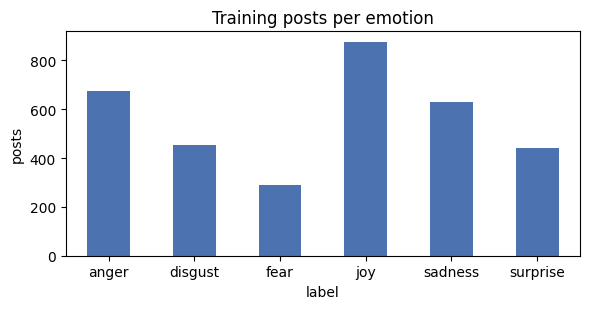

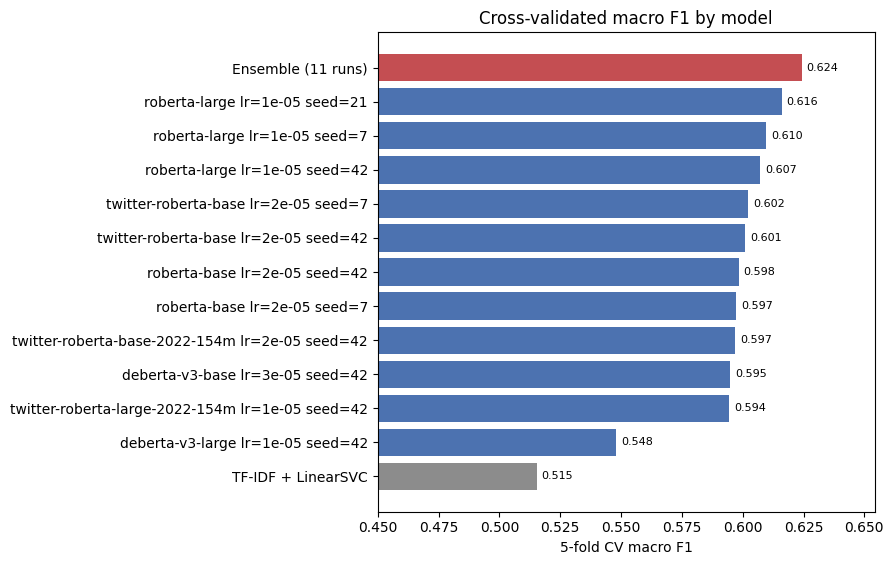

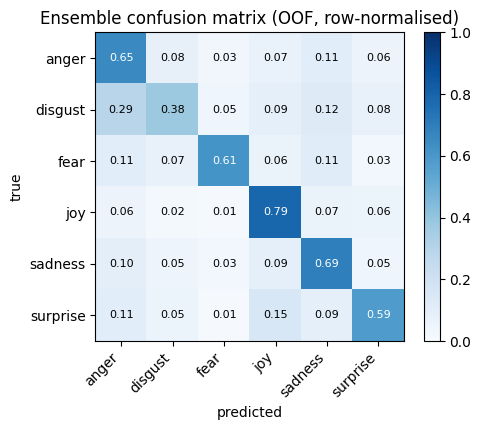

Saved figures to /kaggle/working/figures


In [13]:
# 3.8 Figures for the report: label distribution, CV comparison, and the
# final ensemble's confusion matrix (each row normalised to sum to 1).
import matplotlib.pyplot as plt

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 3.2))
counts.reindex(LABELS).plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Training posts per emotion")
ax.set_ylabel("posts")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "hw_class_distribution.png", dpi=150)
plt.show()

runs_cv = summary.rename(columns={"run": "model", "cv_macro_f1": "cv"})[["model", "cv"]]
runs_cv["model"] = runs_cv["model"].str.split("/").str[-1]      # drop the "organisation/" prefix
comparison = pd.concat([
    pd.DataFrame({"model": ["TF-IDF + LinearSVC"], "cv": [cv_svm]}),
    runs_cv,
    pd.DataFrame({"model": [f"Ensemble ({len(kept)} runs)"], "cv": [cv_ens]}),
]).sort_values("cv")
fig, ax = plt.subplots(figsize=(9, 0.35 * len(comparison) + 1.2))
colors = ["#C44E52" if m.startswith("Ensemble") else "#8C8C8C" if m.startswith("TF-IDF") else "#4C72B0"
          for m in comparison["model"]]
ax.barh(comparison["model"], comparison["cv"], color=colors)
ax.set_xlim(0.45, max(comparison["cv"]) + 0.03)
ax.set_xlabel("5-fold CV macro F1")
ax.set_title("Cross-validated macro F1 by model")
for i, v in enumerate(comparison["cv"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "hw_cv_comparison.png", dpi=150)
plt.show()

cm = confusion_matrix(train_df["label"], ens_pred, labels=LABELS, normalize="true")
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Ensemble confusion matrix (OOF, row-normalised)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG_DIR / "hw_confusion_matrix.png", dpi=150)
plt.show()
print("Saved figures to", FIG_DIR)

In [14]:
# 3.9 Error analysis: which emotions does the final ensemble confuse, and why?
# Both directions of every pair are added (the Lab Exercise 8 method). The
# largest pair is then inspected through the ensemble's probabilities, the
# words in the misclassified posts, and the conflicting duplicate labels from 1.1.
from collections import Counter

ens_idx = ens_oof.argmax(axis=1)
cm_counts = confusion_matrix(y_idx, ens_idx)
pairs = pd.DataFrame(
    [(LABELS[i], LABELS[j], cm_counts[i, j], cm_counts[j, i])
     for i in range(len(LABELS)) for j in range(i + 1, len(LABELS))],
    columns=["class_a", "class_b", "a_predicted_as_b", "b_predicted_as_a"])
pairs["total"] = pairs["a_predicted_as_b"] + pairs["b_predicted_as_a"]
print("Most-confused pairs (OOF predictions, both directions added):")
print(pairs.sort_values("total", ascending=False).head(5).to_string(index=False))

A, G = LABELS.index("anger"), LABELS.index("disgust")
err = np.where((y_idx == G) & (ens_idx == A))[0]          # disgust posts predicted as anger
ok = np.where((y_idx == G) & (ens_idx == G))[0]           # disgust posts predicted correctly
second = np.argsort(-ens_oof[err], axis=1)[:, 1]
print(f"\nDisgust predicted as anger: {len(err)} of {(y_idx == G).sum()} disgust posts; "
      f"anger predicted as disgust: {((y_idx == A) & (ens_idx == G)).sum()} of {(y_idx == A).sum()} anger posts")
print(f"In these errors disgust is the second choice in {np.mean(second == G):.0%} of posts; "
      f"mean p(anger) {ens_oof[err, A].mean():.2f}, mean p(disgust) {ens_oof[err, G].mean():.2f}")


def word_share(rows, word):
    """Share of the given posts whose cleaned text contains the word."""
    return train_df.loc[rows, "text_clean"].str.contains(rf"\b{word}\b").mean()


words = ["disgusting", "gross", "nasty", "fuck", "fucking", "hate", "stupid"]
print("\nShare of disgust posts containing each word:")
print(pd.DataFrame({"predicted anger (error)": [word_share(err, w) for w in words],
                    "predicted disgust (correct)": [word_share(ok, w) for w in words]},
                   index=words).round(3).to_string())

dup_sets = (train_df[train_df.duplicated("text", keep=False)]
            .groupby("text")["label"].agg(lambda s: tuple(sorted(set(s)))))
print("\nDuplicated texts with conflicting labels, by label pair:",
      Counter(dup_sets[dup_sets.map(len) > 1]).most_common(3))

print("\nMost confident disgust -> anger errors:")
for i in err[np.argsort(-ens_oof[err, A])][:5]:
    print(f"  p(anger) {ens_oof[i, A]:.2f}, p(disgust) {ens_oof[i, G]:.2f} | {train_df.at[i, 'text'][:100]}")


Most-confused pairs (OOF predictions, both directions added):
class_a  class_b  a_predicted_as_b  b_predicted_as_a  total
  anger  disgust                54               132    186
  anger  sadness                73                60    133
    joy surprise                54                68    122
    joy  sadness                57                57    114
  anger      joy                46                49     95

Disgust predicted as anger: 132 of 454 disgust posts; anger predicted as disgust: 54 of 674 anger posts
In these errors disgust is the second choice in 83% of posts; mean p(anger) 0.62, mean p(disgust) 0.20

Share of disgust posts containing each word:
            predicted anger (error)  predicted disgust (correct)
disgusting                    0.000                        0.175
gross                         0.008                        0.006
nasty                         0.015                        0.035
fuck                          0.053                        0.018